# Kickstarter: Predicting Whether a Project Gets Funded

## Introduction

Kickstarter is a crowdfunding platform where creators set a funding goal and a deadline. If the goal is not reached by the deadline, the project receives nothing. The aim of this notebook is to **predict, at launch time, whether a project will be successfully funded**, using only information available before the campaign starts: the funding goal, category, country, campaign duration, launch date and time, and the length of the project name.

The target `target_state` is 1 for successful projects and 0 otherwise. Canceled projects are counted as failures (0), because from a creator's point of view a canceled campaign did not get funded. About 36% of the projects are successful, so the classes are imbalanced.

**Metric.** We use the **F1 score** of the successful class as the main metric. Accuracy alone is misleading here: a model that always predicts "failure" already reaches about 64% accuracy while never finding a single successful project. F1 balances precision (how often a predicted success is real) and recall (how many real successes are found). We also report precision, recall, accuracy and ROC AUC.

## Load the Data

In [19]:
import gc
import os

import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv("data/kickstarter_final.csv")
df.head()

,target_state,log10_goal_usd,name_length,duration_days,launch_year,launch_weekday,launch_month,launch_day,launch_hour,country,category,split_group,original_state
0,0,3.185811,31,59,2015,Tuesday,8,11,12,GB,Other,237706,failed
1,0,4.477121,45,60,2017,Saturday,9,2,4,US,Narrative Film,352360,failed
2,0,4.653213,14,45,2013,Saturday,1,12,0,US,Narrative Film,79678,failed
3,0,3.698970,49,30,2012,Saturday,3,17,3,US,Music,46115,failed
4,0,4.290035,58,56,2015,Saturday,7,4,8,US,Film & Video,230745,canceled


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 366690 entries, 0 to 366689
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   target_state    366690 non-null  int64  
 1   log10_goal_usd  366690 non-null  float64
 2   name_length     366690 non-null  int64  
 3   duration_days   366690 non-null  int64  
 4   launch_year     366690 non-null  int64  
 5   launch_weekday  366690 non-null  str    
 6   launch_month    366690 non-null  int64  
 7   launch_day      366690 non-null  int64  
 8   launch_hour     366690 non-null  int64  
 9   country         366690 non-null  str    
 10  category        366690 non-null  str    
 11  split_group     366690 non-null  int64  
 12  original_state  366690 non-null  str    
dtypes: float64(1), int64(8), str(4)
memory usage: 36.4 MB


> ## Data Preparation and Train / Validation / Test Split
>
> We separate the target (`target_state`) from the features and remove `original_state`, which reveals the outcome (data leakage), and `split_group`, which is only a group identifier. The launch weekday is converted to a number (0 = Monday, 6 = Sunday), and `country` and `category` are turned into dummy variables. No scaling is needed for tree-based models.
>
> The data is split into three parts. We first hold out 20% as the **test set**, used only once to evaluate the final model. The remaining 80% is split into a **training set** (68% of the total), used to train the models, and a **validation set** (12%), used to compare models and choose hyperparameters.
>
> We use `GroupShuffleSplit` so that projects in the same `split_group` always end up in the same part. This prevents related projects, such as relaunches, from appearing in both training and evaluation, which would make the results look better than they really are.

In [21]:
y = df["target_state"]
groups = df["split_group"]
X = df.drop(columns=["target_state", "original_state", "split_group"])  # target, leakage and group ID

weekdays = {"Monday": 0, "Tuesday": 1, "Wednesday": 2, "Thursday": 3,
            "Friday": 4, "Saturday": 5, "Sunday": 6}
X["launch_weekday"] = X["launch_weekday"].map(weekdays)
X = pd.get_dummies(X, columns=["country", "category"], dtype=int)

# Train / test (80/20), keeping projects from the same group together
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

# Inside train: training / validation (85/15) to compare and tune the models
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
tr_idx, val_idx = next(gss_val.split(X_train, y_train, groups_train))
X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

print(f"Training: {len(X_tr):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")
print(f"Success rate — training: {y_tr.mean():.1%} | validation: {y_val.mean():.1%} | test: {y_test.mean():.1%}")

Training: 249,365 | Validation: 44,010 | Test: 73,315
Success rate — training: 36.4% | validation: 36.6% | test: 36.4%


> ## Evaluation Function
>
> This helper computes all five metrics for an already trained model on a given dataset, so we don't repeat the same lines for every model.

In [22]:
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, roc_auc_score

def evaluate(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {
        "f1":        f1_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall":    recall_score(y, pred),
        "accuracy":  accuracy_score(y, pred),
        "roc_auc":   roc_auc_score(y, prob),
    }

> ## Model Comparison
>
> We compare a **baseline** (always predict the most frequent class, "failure") with three models: logistic regression, Random Forest and Gradient Boosting. Each model starts with a simple configuration: mostly default parameters, with balanced class weights so the minority class (successful projects) gets more weight.
>
> Each model **learns only from the training set** (`X_tr`), and its performance is **measured on the validation set** (`X_val`), which contains projects it has never seen. The test set is not used at this stage. We also compute the F1 score on the training set, so we can detect overfitting if it is much higher than the validation F1.

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    # Logistic regression needs scaling (inside the pipeline so it is fitted on training data only)
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    # Lighter settings to avoid running out of memory: each tree sees 30% of the rows, 2 CPU cores
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=20, min_samples_leaf=5, max_samples=0.3,
        class_weight="balanced", n_jobs=2, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=42),
}

rows = {}
for name, model in models.items():
    model.fit(X_tr, y_tr)
    rows[name] = {**{f"{k}_val": v for k, v in evaluate(model, X_val, y_val).items()},
                  "f1_train": f1_score(y_tr, model.predict(X_tr))}
    print(f"{name} trained")

comparison = pd.DataFrame(rows).T.round(4).sort_values("f1_val", ascending=False)
display(comparison)

# Free memory before the tuning step
del models
gc.collect()

Baseline trained
Logistic Regression trained
Random Forest trained
Gradient Boosting trained


,f1_val,precision_val,recall_val,accuracy_val,roc_auc_val,f1_train
Gradient Boosting,0.6236,0.5518,0.7170,0.6835,0.7599,0.6242
Random Forest,0.6092,0.5334,0.7103,0.6667,0.7453,0.6258
Logistic Regression,0.5885,0.5278,0.6651,0.6598,0.7242,0.5826
Baseline,0.0000,0.0000,0.0000,0.6342,0.5000,0.0000


7083

> ## Hyperparameter Tuning
>
> To find the best settings for each model, we try every combination of a small set of hyperparameter values. For each combination, the model is trained on the training set and evaluated on the validation set, and we keep the combination with the highest F1 score. This works like a grid search, but with a single validation split instead of cross-validation, which is faster with a dataset of this size. The test set is still not used. Hyperparameters are chosen by this search, while the model's internal parameters are learned during training by each algorithm's own method (for example, gradient-based optimization in Gradient Boosting and Logistic Regression).

In [24]:
from sklearn.model_selection import ParameterGrid

def tune(make_model, params):
    """Train each parameter combination once and evaluate it on the validation set."""
    rows = []
    for combo in ParameterGrid(params):
        model = make_model(**combo)
        model.fit(X_tr, y_tr)
        res = evaluate(model, X_val, y_val)
        rows.append({**combo, **res})
        print(combo, f"→ F1 {res['f1']:.4f}")
    return pd.DataFrame(rows).sort_values("f1", ascending=False).round(4)

> ### Logistic Regression
>
> The features are first standardized with `StandardScaler`, inside a pipeline so the scaling is learned from the training set only. We then try 8 combinations of two hyperparameters: `C` (0.01, 0.1, 1, 10), which controls regularization (lower values give a simpler model and help prevent overfitting), and `class_weight` (`None` or `"balanced"`), which gives more weight to the minority class (successful projects). The table shows the five best combinations ranked by validation F1.

In [25]:
res_log = tune(
    lambda **p: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, **p)),
    {"C": [0.01, 0.1, 1, 10],                 # lower C = simpler model
     "class_weight": [None, "balanced"]},
)
display(res_log.head())

{'C': 0.01, 'class_weight': None} → F1 0.4798
{'C': 0.01, 'class_weight': 'balanced'} → F1 0.5885
{'C': 0.1, 'class_weight': None} → F1 0.4802
{'C': 0.1, 'class_weight': 'balanced'} → F1 0.5885
{'C': 1, 'class_weight': None} → F1 0.4803
{'C': 1, 'class_weight': 'balanced'} → F1 0.5885
{'C': 10, 'class_weight': None} → F1 0.4803
{'C': 10, 'class_weight': 'balanced'} → F1 0.5885


,C,class_weight,f1,precision,recall,accuracy,roc_auc
3,0.10,balanced,0.5885,0.5278,0.6651,0.6598,0.7242
1,0.01,balanced,0.5885,0.5278,0.6651,0.6598,0.7242
7,10.00,balanced,0.5885,0.5278,0.6651,0.6598,0.7242
5,1.00,balanced,0.5885,0.5278,0.6651,0.6598,0.7242
4,1.00,NaN,0.4803,0.6146,0.3942,0.6880,0.7241


> ### Random Forest
>
> A Random Forest builds many decision trees, each trained on a random sample of the rows and features, and combines their votes. To keep memory use under control, we use 100 trees, each trained on 30% of the rows, with balanced class weights. We then try 18 combinations of three hyperparameters: `max_depth` (10, 15, 20), the maximum depth of each tree; `min_samples_leaf` (5, 20, 50), the minimum number of projects per leaf (higher values give simpler trees); and `max_features` (`"sqrt"` or 0.3), the share of features considered at each split. The table shows the five best combinations ranked by validation F1.

In [26]:
res_rf = tune(
    lambda **p: RandomForestClassifier(
        n_estimators=100,        # fewer trees during the search to save time and memory
        max_samples=0.3,         # each tree sees 30% of the rows
        class_weight="balanced",
        n_jobs=2,                # 2 cores instead of all of them: less memory at the same time
        random_state=42, **p),
    {"max_depth": [10, 15, 20],          # no unlimited depth: very deep trees fill the memory
     "min_samples_leaf": [5, 20, 50],    # higher = simpler trees, less overfitting
     "max_features": ["sqrt", 0.3]},     # features considered at each split
)
display(res_rf.head())
gc.collect()

{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5} → F1 0.5938
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 20} → F1 0.5945
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 50} → F1 0.5941
{'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 5} → F1 0.5984
{'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 20} → F1 0.5984
{'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 50} → F1 0.5970
{'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5} → F1 0.6031
{'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 20} → F1 0.6006
{'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 50} → F1 0.6013
{'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 5} → F1 0.6089
{'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 20} → F1 0.6081
{'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 50} → F1 0.6057
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 5} → F1 0.6092
{'max_dep

,max_depth,max_features,min_samples_leaf,f1,precision,recall,accuracy,roc_auc
15,20,0.3,5,0.6133,0.5417,0.7069,0.6740,0.7481
16,20,0.3,20,0.6121,0.5390,0.7083,0.6717,0.7451
12,20,sqrt,5,0.6092,0.5334,0.7103,0.6667,0.7453
9,15,0.3,5,0.6089,0.5339,0.7086,0.6671,0.7426
10,15,0.3,20,0.6081,0.5313,0.7107,0.6649,0.7406


744

> ### Gradient Boosting
>
> Gradient Boosting builds trees one after another, each one correcting the errors of the previous ones. No scaling is needed, and we use balanced class weights. We then try 12 combinations of three hyperparameters: `learning_rate` (0.05, 0.1), the size of each correction step; `max_leaf_nodes` (15, 31, 63), the complexity of each tree; and `min_samples_leaf` (20, 100), the minimum number of projects per leaf (higher values give simpler trees). The table shows the five best combinations ranked by validation F1.

In [27]:
res_gb = tune(
    lambda **p: HistGradientBoostingClassifier(class_weight="balanced", random_state=42, **p),
    {"learning_rate": [0.05, 0.1],            # size of each correction step
     "max_leaf_nodes": [15, 31, 63],          # complexity of each tree
     "min_samples_leaf": [20, 100]},          # minimum projects per leaf
)
display(res_gb.head())

{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 20} → F1 0.6117
{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 100} → F1 0.6117
{'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 20} → F1 0.6191
{'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 100} → F1 0.6183
{'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 20} → F1 0.6212
{'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 100} → F1 0.6212
{'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 20} → F1 0.6189
{'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 100} → F1 0.6188
{'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 20} → F1 0.6236
{'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 100} → F1 0.6221
{'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 20} → F1 0.6243
{'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 100} → F1 0.6245


,learning_rate,max_leaf_nodes,min_samples_leaf,f1,precision,recall,accuracy,roc_auc
11,0.10,63,100,0.6245,0.5539,0.7157,0.6852,0.7617
10,0.10,63,20,0.6243,0.5536,0.7157,0.6849,0.7611
8,0.10,31,20,0.6236,0.5518,0.7170,0.6835,0.7599
9,0.10,31,100,0.6221,0.5511,0.7141,0.6827,0.7599
5,0.05,63,100,0.6212,0.5489,0.7156,0.6808,0.7577


> ## Comparison of the Best Models
>
> We compare the best version of each model on the validation set and select the one with the highest F1.

In [28]:
best = pd.DataFrame({
    "Logistic Regression": res_log.iloc[0],
    "Random Forest":       res_rf.iloc[0],
    "Gradient Boosting":   res_gb.iloc[0],
}).T
display(best[["f1", "precision", "recall", "accuracy", "roc_auc"]].astype(float).round(4))

,f1,precision,recall,accuracy,roc_auc
Logistic Regression,0.5885,0.5278,0.6651,0.6598,0.7242
Random Forest,0.6133,0.5417,0.7069,0.6740,0.7481
Gradient Boosting,0.6245,0.5539,0.7157,0.6852,0.7617


> Gradient Boosting achieves the best validation score on every metric (F1 of about 0.625 and ROC AUC of about 0.762), followed by Random Forest and logistic regression. The differences between models are small, which suggests that the limit comes from the information in the features rather than from the choice of algorithm.

> ## Final Model and Test Evaluation
>
> Gradient Boosting achieved the best validation F1, so we select it as the final model. The `clean_params` function takes its best hyperparameters from the tuning table and converts them into the format scikit-learn expects (for example, `20.0` becomes `20` and `NaN` becomes `None`). We then retrain the model on the whole training set (training + validation), so it learns from as much data as possible, and evaluate it **once** on the test set, which it has never seen.
>
> To check for overfitting or underfitting, we compare the final model's scores on the training, validation and test sets. A large gap between training and test scores would indicate overfitting, while low scores on all sets would indicate underfitting.

In [29]:
def clean_params(row, names):
    """Turn a results row into valid parameters (NaN -> None, 20.0 -> 20)."""
    p = {}
    for k in names:
        v = row[k]
        if isinstance(v, float) and np.isnan(v):
            v = None
        elif isinstance(v, float) and v.is_integer() and k != "max_features":
            v = int(v)
        p[k] = v
    return p

# Best parameters of the winning model (Gradient Boosting)
p = clean_params(res_gb.iloc[0], ["learning_rate", "max_leaf_nodes", "min_samples_leaf"])
print("Best parameters:", p)

final_model = HistGradientBoostingClassifier(class_weight="balanced", random_state=42, **p)
final_model.fit(X_train, y_train)          # with the WHOLE training set (training + validation)

# Compare train, validation and test to check for overfitting / underfitting
results = pd.DataFrame({
    "train":      evaluate(final_model, X_train, y_train),                               # data the model learned from
    "validation": res_gb.iloc[0][["f1", "precision", "recall", "accuracy", "roc_auc"]],  # from the tuning step
    "test":       evaluate(final_model, X_test, y_test),                                 # never seen before
}).astype(float).round(4)
results["train - test"] = (results["train"] - results["test"]).round(4)

print("\n=== FINAL MODEL: TRAIN vs VALIDATION vs TEST ===")
display(results)
print(f"Baseline on test: F1 = 0.00, accuracy = {(y_test == 0).mean():.4f}")

Best parameters: {'learning_rate': np.float64(0.1), 'max_leaf_nodes': 63, 'min_samples_leaf': 100}

=== FINAL MODEL: TRAIN vs VALIDATION vs TEST ===


,train,validation,test,train - test
f1,0.6313,0.6245,0.6210,0.0103
precision,0.5575,0.5539,0.5479,0.0096
recall,0.7278,0.7157,0.7166,0.0112
accuracy,0.6902,0.6852,0.6814,0.0088
roc_auc,0.7714,0.7617,0.7583,0.0131


Baseline on test: F1 = 0.00, accuracy = 0.6357


> The final model performs almost identically on the training, validation and test sets: the gap between training and test is about 0.01 for every metric (F1 of 0.631 on training and 0.621 on test). This shows that the model **generalizes well and is not overfitting**. It also clearly beats the baseline (F1 of 0.62 against 0, accuracy of 0.68 against 0.64), so it has learned real patterns.

> ### Confusion Matrix
>
> The confusion matrix shows the four possible outcomes on the test set: correctly predicted failures and successes, and the two types of error.

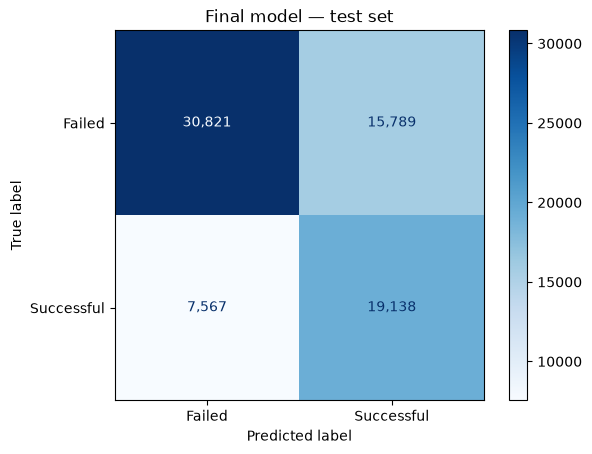

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

y_test_prob = final_model.predict_proba(X_test)[:, 1]
y_test_pred = final_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["Failed", "Successful"], cmap="Blues", values_format=","
)
plt.title("Final model — test set")
plt.show()

> Overall the model classifies about 2 out of 3 projects correctly. It finds most of the successful projects (recall of about 0.72), but many of its "success" predictions are wrong (precision of about 0.55). This is the effect of the balanced class weights: the model leans towards predicting success.

> ### Decision Threshold
>
> By default, the model predicts "success" when its probability is at least 0.5. Raising this threshold makes it more cautious: precision goes up and recall goes down. The table shows this trade-off on the test set. It is shown for illustration only; the reported results use the default threshold of 0.5, because choosing the threshold on the test set would bias the evaluation.

In [31]:
threshold_table = pd.DataFrame([
    {
        "threshold": t,
        "precision": precision_score(y_test, (y_test_prob >= t).astype(int)),
        "recall":    recall_score(y_test, (y_test_prob >= t).astype(int)),
        "f1":        f1_score(y_test, (y_test_prob >= t).astype(int)),
        "accuracy":  accuracy_score(y_test, (y_test_prob >= t).astype(int)),
    }
    for t in [0.5, 0.55, 0.6, 0.65, 0.7]
]).round(3)
display(threshold_table)

,threshold,precision,recall,f1,accuracy
0,0.50,0.548,0.717,0.621,0.681
1,0.55,0.576,0.634,0.604,0.697
2,0.60,0.606,0.546,0.575,0.705
3,0.65,0.641,0.447,0.527,0.707
4,0.70,0.677,0.334,0.447,0.699


> Raising the threshold from 0.5 to 0.6 increases precision from about 0.55 to 0.61, but recall drops from about 0.72 to 0.55. In other words, a more cautious model is right more often when it predicts success, but misses almost half of the successful projects. Which threshold is best depends on the use case: a creator who wants a reliable warning would prefer a higher threshold, while a platform that wants to spot promising projects would prefer a lower one.

> ## Feature Importance
>
> To understand **what drives success**, we measure how much the model's ROC AUC drops when the values of one feature are randomly shuffled (permutation importance). The more the score drops, the more the model relies on that feature. The dummy columns of `country` and `category` are shuffled together, so each original feature gets a single importance value. We use a sample of 20,000 test projects to keep it fast.

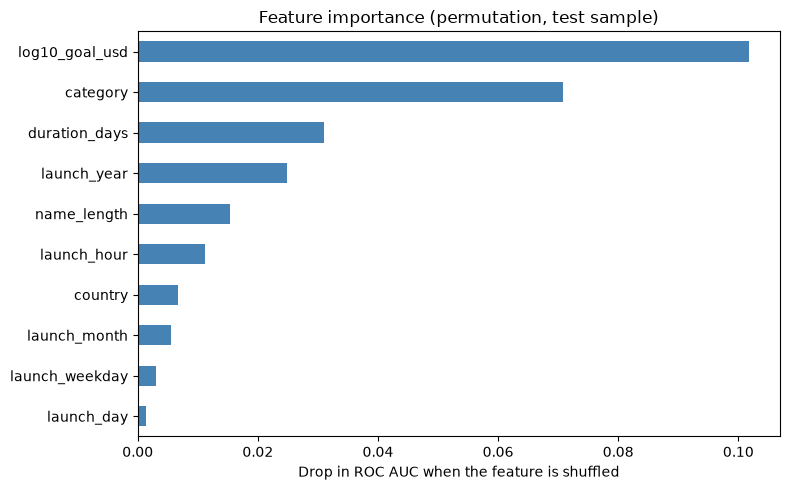

,AUC drop
log10_goal_usd,0.1018
category,0.0709
duration_days,0.0310
launch_year,0.0249
name_length,0.0153
launch_hour,0.0112
country,0.0066
launch_month,0.0055
launch_weekday,0.0030
launch_day,0.0013


In [32]:
# Group the dummy columns back into their original feature
feature_groups = {col: [col] for col in ["log10_goal_usd", "name_length", "duration_days", "launch_year",
                                         "launch_weekday", "launch_month", "launch_day", "launch_hour"]}
feature_groups["country"] = [c for c in X.columns if c.startswith("country_")]
feature_groups["category"] = [c for c in X.columns if c.startswith("category_")]

X_sample = X_test.sample(min(20_000, len(X_test)), random_state=42)
y_sample = y_test.loc[X_sample.index]
base_auc = roc_auc_score(y_sample, final_model.predict_proba(X_sample)[:, 1])

rng = np.random.default_rng(42)
importance = {}
for feature, cols in feature_groups.items():
    drops = []
    for _ in range(3):                                   # 3 repetitions for a more stable estimate
        X_perm = X_sample.copy()
        X_perm[cols] = X_sample[cols].values[rng.permutation(len(X_sample))]
        drops.append(base_auc - roc_auc_score(y_sample, final_model.predict_proba(X_perm)[:, 1]))
    importance[feature] = np.mean(drops)

importance = pd.Series(importance).sort_values()
importance.plot.barh(figsize=(8, 5), color="steelblue")
plt.xlabel("Drop in ROC AUC when the feature is shuffled")
plt.title("Feature importance (permutation, test sample)")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).round(4).to_frame("AUC drop"))

> The **funding goal** is by far the most important feature: shuffling it lowers the ROC AUC by about 0.10. Projects with lower goals are much more likely to succeed. The **category** comes second (about 0.07), confirming that some kinds of projects (such as games, comics or theater) succeed much more often than others (such as technology or food). **Campaign duration** and **launch year** follow, while the launch weekday, month, day and hour, and the country, have very little influence. In practice, what a creator decides about the goal and the type of project matters far more than when exactly the campaign is launched.

> ## Save the Model

In [33]:
os.makedirs("models", exist_ok=True)
joblib.dump(final_model, "models/kickstarter_gradient_boosting.joblib")
print("Model saved to models/kickstarter_gradient_boosting.joblib")

Model saved to models/kickstarter_gradient_boosting.joblib


> ## Conclusion
>
> We trained and compared three models to predict, at launch time, whether a Kickstarter project will be funded. After tuning their hyperparameters on a validation set, **Gradient Boosting** gave the best results. On the test set it reaches an **F1 of 0.62** and a **ROC AUC of 0.76**, clearly above the baseline (F1 of 0), and it classifies about 2 out of 3 projects correctly. The training, validation and test scores are very close, so the model generalizes well and does not overfit.
>
> The most important drivers of success are the **funding goal** and the **category**, followed by the campaign duration. The exact launch date and time have little effect.
>
> **Limitations.** Even on the training set the F1 only reaches about 0.63, which shows that the limit comes from the available features rather than from the model: the three algorithms give similar results. The dataset only describes the project at launch, while key drivers of success, such as the campaign description, video, reward tiers or the creator's audience, are not included. The model also leans towards optimism (precision of about 0.55), which could be adjusted with a higher decision threshold depending on the use case.
>
> **Next steps.** The most promising improvement is adding text features from the project name or description (making sure to remove the "(Canceled)" suffix that Kickstarter adds after a campaign ends, to avoid data leakage). Choosing the decision threshold on the validation set, and checking the model on later years only, would also make the evaluation closer to real use.